# EvalForge — a verifier‑first coding‑agent research harness

**What this is.** EvalForge is a small, honest research harness for asking a
concrete question about LLM coding agents:

> *Do a persistent, cross‑task **memory** and a mandatory, evidence‑linked
> **verifier loop** actually make an agent better at fixing bugs — or do they
> just add machinery?*

To answer that fairly you need three things that are easy to get wrong:
a **benchmark** of bugs where "solved" is defined by tests the agent can't see;
a **contained agent** that can only act through audited tools and can never
declare its own victory; and an **ablation** that changes exactly one thing at a
time. This notebook implements all three, end to end, in pure Python.

**Three conditions we compare** (identical harness, one variable each):

| Condition | Tools + visible tests | Persistent memory | Evidence‑linked verifier loop |
|---|:---:|:---:|:---:|
| `baseline` | ✅ | — | — |
| `memory` | ✅ | ✅ | — |
| `memory_verifier` | ✅ | ✅ | ✅ |

**An honest note up front.** So it needs no API keys, this notebook drives the
agent with a **scripted provider** that replays *pre‑validated* repair steps.
That makes it a faithful, deterministic test of **the harness** — the state
machine, the containment, the memory plumbing, the scoring. It is *not* a
measurement of model intelligence: because every scripted repair is known‑good,
all three conditions will resolve every task. The scientific payoff of the
ablation appears when you replace the scripted provider with a real LLM (the
last section shows exactly where). Keeping that distinction crisp is the point.

## How to run this

1. Put **`evalforge_benchmark_data.json`** (shipped alongside this notebook) in
   the same folder as the notebook.
2. Run the cells top to bottom. The setup cell installs `numpy`, `pandas`,
   `pytest`, and `matplotlib` into *this kernel* (nothing global is touched).
3. Expect roughly **1–2 minutes** total — the ablation actually spins up a fresh
   git repo and runs real `pytest` for every one of 60 held‑out runs.

**Prerequisites:** Python ≥ 3.10 and `git` on your `PATH`. That's it. The PyTorch
tasks use lightweight in‑test doubles, so you do **not** need a GPU or `torch`.

**Roadmap.** Parts 1–11 build the engine (each concept explained, then
implemented). The **Demos** then load the real benchmark, validate it, walk a
single repair step‑by‑step, run the full three‑way ablation, and plot the
trace‑derived metrics.

## Setup — install dependencies and check the environment

In [4]:
# Installs into THIS kernel only (safe; nothing global is modified).
%pip install -q numpy pandas pytest matplotlib

import shutil, sys
import numpy, pandas, matplotlib

print("python  :", sys.version.split()[0])
print("numpy   :", numpy.__version__)
print("pandas  :", pandas.__version__)
print("git     :", "found at " + shutil.which("git") if shutil.which("git") else "MISSING — please install git")
assert shutil.which("git"), "git is required (workspaces are real git repos)"
import pytest  # noqa: F401  (invoked as `python -m pytest` by the verifier)
print("pytest  :", pytest.__version__)

Note: you may need to restart the kernel to use updated packages.
python  : 3.12.2
numpy   : 1.26.4
pandas  : 2.2.3
git     : found at /usr/bin/git
pytest  : 7.4.4


---
# The engine

The next eleven cells are the complete implementation. Each is preceded by a
short explanation. Run them in order; every cell defines names the later ones
use.

### Imports and a UTC clock

Standard library only — the harness itself has zero third‑party dependencies. `numpy`/`pandas`/`pytest` are needed only to *run the benchmark tasks*, and `matplotlib` only for the plots.

In [8]:
from __future__ import annotations

import json
import re
import shutil
import sqlite3
import subprocess
import sys
import tempfile
import time
import uuid
from collections import Counter, defaultdict, deque
from dataclasses import dataclass, field, asdict
from datetime import datetime, timezone
from enum import Enum
from pathlib import Path
from typing import Any, Iterable, Optional


def utc_now() -> datetime:
    return datetime.now(timezone.utc)

## Part 1 — Typed contracts (the vocabulary of a run)

Everything the harness passes around is a typed object. This is not decoration:
the types *encode the trust boundary*. Study the shapes below and you already
understand the system.

* **`AgentState`** — the eight legal phases of a repair. The agent can only ever
  be in one of these, and can only move between them along declared edges (Part 3).
* **`AgentDecision`** — the *only* thing a provider (the LLM, or our scripted
  stand‑in) is allowed to emit. It can ask for a **tool**, **submit**, or **abort**.
  Notice what is absent: there is no field that lets the model declare the task
  solved, run a raw OS command, or touch a file directly. It can only *propose*.
* **`FailureDiagnosis`** — an evidence‑linked explanation of a failing test.
  This is the heart of the "verifier" treatment: before the agent is allowed to
  edit again, it must cite an exact fragment of the latest test output. A model
  cannot hand‑wave past a red test.
* **`VerificationResult` / `RunSummary` / `MemoryRecord`** — the harness‑owned
  records of what actually happened. Only the harness writes these, and only the
  harness sets `resolved=True`.

`Budget` caps iterations, tool calls, tokens, cost, and wall‑clock so a run
always terminates. `Condition` names the three ablations we compare.

In [11]:
class AgentState(str, Enum):
    TASK_RECEIVED = "task_received"
    INSPECT_REPOSITORY = "inspect_repository"
    RETRIEVE_MEMORY = "retrieve_memory"
    PLAN_REPAIR = "plan_repair"
    EDIT_FILES = "edit_files"
    RUN_VERIFIER = "run_verifier"
    DIAGNOSE_RESULT = "diagnose_result"
    FINISHED = "finished"


class TerminationReason(str, Enum):
    TESTS_PASSED = "tests_passed"
    MAX_ITERATIONS = "max_iterations"
    MAX_TOOL_CALLS = "max_tool_calls"
    MAX_TOKENS = "max_tokens"
    MAX_COST = "max_cost"
    ENVIRONMENT_FAILURE = "environment_failure"
    PROVIDER_ABORT = "provider_abort"
    INVALID_ACTION = "invalid_action"
    EVALUATOR_FAILED = "evaluator_failed"


class ActionKind(str, Enum):
    TOOL = "tool"
    SUBMIT = "submit"
    ABORT = "abort"


class Condition(str, Enum):
    BASELINE = "baseline"
    MEMORY = "memory"
    MEMORY_VERIFIER = "memory_verifier"
    SCRIPTED = "scripted"


@dataclass
class Budget:
    max_iterations: int = 8
    max_tool_calls: int = 40
    max_tokens: Optional[int] = None
    max_cost_usd: Optional[float] = None
    command_timeout_seconds: float = 60.0


@dataclass
class TaskMetadata:
    task_id: str
    title: str
    repository: str
    category: str
    difficulty: str
    visible_test_command: list[str]
    evaluator_test_command: list[str]
    expected_failure: str
    dependencies: list[str] = field(default_factory=list)
    tags: list[str] = field(default_factory=list)
    schema_version: str = "1.0"


@dataclass
class TaskSpec:
    root: Path
    issue: str
    metadata: TaskMetadata

    @property
    def repo_dir(self) -> Path:
        return self.root / "repo"

    @property
    def evaluator_tests_dir(self) -> Path:
        return self.root / "tests"


@dataclass
class FailureDiagnosis:
    """Evidence-linked diagnosis required by the verifier-loop treatment."""
    failed_test: str
    evidence: list[str]
    mechanism: str
    next_change: str


@dataclass
class AgentDecision:
    kind: ActionKind
    plan: Optional[str] = None
    diagnosis: Optional[Any] = None  # FailureDiagnosis | str | None
    lesson: Optional[str] = None
    tool_name: Optional[str] = None
    arguments: dict[str, Any] = field(default_factory=dict)

    def __post_init__(self) -> None:
        if isinstance(self.kind, str):
            self.kind = ActionKind(self.kind)
        if isinstance(self.diagnosis, dict):
            self.diagnosis = FailureDiagnosis(**self.diagnosis)
        if self.kind is ActionKind.TOOL and not self.tool_name:
            raise ValueError("tool actions require tool_name")
        if self.kind is not ActionKind.TOOL and self.tool_name is not None:
            raise ValueError("only tool actions may include tool_name")

    def to_json(self) -> dict[str, Any]:
        d = asdict(self)
        d["kind"] = self.kind.value
        return d


@dataclass
class Usage:
    input_tokens: Optional[int] = None
    output_tokens: Optional[int] = None
    estimated_cost_usd: Optional[float] = None

    @property
    def total_tokens(self) -> Optional[int]:
        if self.input_tokens is None and self.output_tokens is None:
            return None
        return (self.input_tokens or 0) + (self.output_tokens or 0)


@dataclass
class ProviderResponse:
    decision: AgentDecision
    raw_text: Optional[str] = None
    usage: Usage = field(default_factory=Usage)


@dataclass
class ToolResult:
    tool_name: str
    ok: bool
    output: str = ""
    exit_code: Optional[int] = None
    runtime_seconds: float = 0.0
    truncated: bool = False


@dataclass
class VerificationResult:
    command: list[str]
    exit_code: int
    passed: bool
    output: str
    runtime_seconds: float
    tests_collected: Optional[int] = None
    tests_passed: Optional[int] = None
    tests_failed: Optional[int] = None
    environment_error: bool = False


@dataclass
class TaskValidationResult:
    task_id: str
    valid: bool
    buggy_state_failed: bool
    reference_patch_applied: bool
    repaired_state_passed: bool
    buggy_verification: VerificationResult
    repaired_verification: Optional[VerificationResult] = None
    error: Optional[str] = None


@dataclass
class RunSummary:
    run_id: str
    task_id: str
    condition: Condition
    started_at: datetime
    finished_at: datetime
    termination_reason: TerminationReason
    resolved: bool
    iterations: int
    tool_calls: int
    runtime_seconds: float
    trace_path: str
    workspace_path: str
    visible_verification: Optional[VerificationResult] = None
    evaluator_verification: Optional[VerificationResult] = None
    changed_files: list[str] = field(default_factory=list)
    patch_valid: bool = True
    regression_detected: bool = False
    usage: Usage = field(default_factory=Usage)
    provider: str = "unknown"
    model: Optional[str] = None
    retrieved_memory_ids: list[int] = field(default_factory=list)


@dataclass
class MemoryRecord:
    repository: str
    task_id: str
    task_category: str
    error_signature: str
    lesson: str
    trace_id: str
    verifier_evidence: str
    outcome: str  # "resolved" | "failed"
    memory_id: Optional[int] = None
    repair_pattern: str = ""
    failed_approach: str = ""
    tags: list[str] = field(default_factory=list)
    created_at: datetime = field(default_factory=utc_now)
    schema_version: str = "1.0"

    def as_context(self) -> str:
        return (
            f"[{self.task_category}] {self.lesson} "
            f"Repair pattern: {self.repair_pattern or 'not recorded'}. "
            f"Evidence source: {self.trace_id}."
        )

## Part 2 — Loading the benchmark

Each task in the data file is a self‑contained bug‑fix problem: a **buggy
repository** (with agent‑visible tests), a set of **protected evaluator tests**
the agent never sees, a plain‑English **issue**, structured **metadata**, a
known‑good **reference patch**, and a deterministic **scripted repair** we can
replay without any API key.

`materialize_task` writes one bundled task back onto disk so the rest of the
machinery — which expects real files, a real git repo, and real `pytest` — runs
completely unmodified. This is the bridge between the portable JSON you were
given and a faithful execution.

In [14]:
def load_dataset(json_path: Path) -> list[dict]:
    payload = json.loads(Path(json_path).read_text(encoding="utf-8"))
    return payload["tasks"]


def materialize_task(task_json: dict, dest_root: Path) -> TaskSpec:
    """Write a bundled task back to disk so the on-disk machinery works unchanged."""
    root = Path(dest_root) / f"{task_json['suite']}_{task_json['name']}"
    root.mkdir(parents=True, exist_ok=True)
    (root / "issue.md").write_text(task_json["issue"], encoding="utf-8")
    (root / "metadata.json").write_text(json.dumps(task_json["metadata"]), encoding="utf-8")
    (root / "reference_patch.diff").write_text(task_json["reference_patch"], encoding="utf-8")
    for rel, content in task_json["repo_files"].items():
        p = root / "repo" / rel
        p.parent.mkdir(parents=True, exist_ok=True)
        p.write_text(content, encoding="utf-8")
    for rel, content in task_json["evaluator_files"].items():
        p = root / "tests" / rel
        p.parent.mkdir(parents=True, exist_ok=True)
        p.write_text(content, encoding="utf-8")
    metadata = TaskMetadata(**task_json["metadata"])
    return TaskSpec(root=root, issue=task_json["issue"].strip(), metadata=metadata)


def decisions_from_script(script: list[dict]) -> list[AgentDecision]:
    return [AgentDecision(**item) for item in script]

## Part 3 — The state machine

Why bother? Because "an agent in a `while` loop" is unauditable. By declaring the
legal transitions up front, every run becomes a walk through a small graph, and
illegal jumps — e.g. `task_received` straight to `edit_files`, skipping
inspection, memory retrieval, and planning — raise a hard error instead of
passing silently. `ALLOWED_TRANSITIONS` *is* that ordering policy.

Note what the table deliberately *does* permit: `plan_repair → edit_files`. The
state machine governs **ordering**, not **evidence** — it does not, by itself,
forbid a first edit before a red test. The stricter "you may not edit until
you've cited a failing test" rule is a separate, condition‑specific gate we'll
meet in the orchestrator (Part 10) under `memory_verifier`.

In [17]:
class InvalidTransition(ValueError):
    pass


ALLOWED_TRANSITIONS: dict[AgentState, frozenset[AgentState]] = {
    AgentState.TASK_RECEIVED: frozenset({AgentState.INSPECT_REPOSITORY}),
    AgentState.INSPECT_REPOSITORY: frozenset({AgentState.RETRIEVE_MEMORY}),
    AgentState.RETRIEVE_MEMORY: frozenset({AgentState.PLAN_REPAIR}),
    AgentState.PLAN_REPAIR: frozenset(
        {AgentState.EDIT_FILES, AgentState.RUN_VERIFIER, AgentState.FINISHED}
    ),
    AgentState.EDIT_FILES: frozenset(
        {AgentState.EDIT_FILES, AgentState.RUN_VERIFIER, AgentState.DIAGNOSE_RESULT}
    ),
    AgentState.RUN_VERIFIER: frozenset({AgentState.DIAGNOSE_RESULT, AgentState.FINISHED}),
    AgentState.DIAGNOSE_RESULT: frozenset(
        {AgentState.PLAN_REPAIR, AgentState.EDIT_FILES,
         AgentState.RUN_VERIFIER, AgentState.FINISHED}
    ),
    AgentState.FINISHED: frozenset(),
}


@dataclass
class StateMachine:
    state: AgentState = AgentState.TASK_RECEIVED

    def transition(self, target: AgentState) -> AgentState:
        if target not in ALLOWED_TRANSITIONS[self.state]:
            raise InvalidTransition(f"cannot transition from {self.state} to {target}")
        self.state = target
        return self.state

## Part 4 — The isolated workspace

Each run gets a throwaway **copy** of the buggy repo, initialised as a fresh git
repository with a single "buggy task baseline" commit. The canonical task on disk
is never mutated. Git then does double duty as an oracle:

* `changed_files()` — exactly what the agent touched (diff + untracked), so we
  can report the produced patch.
* `patch_is_valid()` — `git diff --check` rejects whitespace‑corrupt or
  conflict‑marker patches. A green test on a malformed diff does **not** count as
  resolved.

In [20]:
def _git(args: list[str], cwd: Path) -> subprocess.CompletedProcess:
    return subprocess.run(["git", *args], cwd=cwd, capture_output=True, text=True)


@dataclass(frozen=True)
class TaskWorkspace:
    run_id: str
    path: Path

    @classmethod
    def create(cls, task: TaskSpec, run_root: Path, run_id: str) -> "TaskWorkspace":
        destination = (Path(run_root).resolve() / run_id / "workspace").resolve()
        destination.parent.mkdir(parents=True, exist_ok=False)
        shutil.copytree(task.repo_dir, destination)
        for cmd in (
            ["init", "-q"],
            ["config", "user.name", "EvalForge"],
            ["config", "user.email", "evalforge@localhost"],
            ["add", "--all"],
            ["commit", "-q", "-m", "buggy task baseline"],
        ):
            done = _git(cmd, destination)
            if done.returncode != 0:
                raise RuntimeError(f"git workspace init failed: {done.stderr.strip()}")
        return cls(run_id=run_id, path=destination)

    def changed_files(self) -> list[str]:
        modified = _git(["diff", "--name-only", "HEAD"], self.path).stdout.splitlines()
        untracked = _git(
            ["ls-files", "--others", "--exclude-standard"], self.path
        ).stdout.splitlines()
        return sorted(set(modified + untracked))

    def patch_is_valid(self) -> bool:
        if not (self.path / ".git").is_dir():
            return False
        return _git(["diff", "--check", "HEAD"], self.path).returncode == 0

## Part 5 — Repository‑contained filesystem tools

The agent reads and edits only through these methods, and every path is resolved
and checked to stay inside the workspace (`PathViolation` otherwise) — no
`../../etc/passwd`. Output is length‑bounded so a giant file can't blow up the
context window. `apply_patch` goes through `git apply --check` first, so a patch
that wouldn't apply cleanly is rejected before it can corrupt the tree.

In [23]:
class PathViolation(ValueError):
    pass


class FileSystemTools:
    def __init__(self, root: Path, *, max_output_chars: int = 30_000) -> None:
        self.root = Path(root).resolve()
        self.max_output_chars = max_output_chars

    def _resolve(self, relative_path: str) -> Path:
        if not relative_path or "\x00" in relative_path:
            raise PathViolation("path must be non-empty and NUL-free")
        candidate = (self.root / relative_path).resolve()
        try:
            candidate.relative_to(self.root)
        except ValueError as exc:
            raise PathViolation(f"path escapes workspace: {relative_path}") from exc
        return candidate

    def _bounded(self, value: str) -> tuple[str, bool]:
        if len(value) <= self.max_output_chars:
            return value, False
        return value[: self.max_output_chars] + "\n... output truncated ...", True

    def list_files(self, pattern: str = "*") -> ToolResult:
        started = time.monotonic()
        paths = sorted(
            str(p.relative_to(self.root))
            for p in self.root.rglob(pattern)
            if p.is_file() and ".git" not in p.parts
        )
        output, truncated = self._bounded("\n".join(paths))
        return ToolResult("list_files", True, output,
                          runtime_seconds=time.monotonic() - started, truncated=truncated)

    def read_file(self, path: str) -> ToolResult:
        started = time.monotonic()
        target = self._resolve(path)
        if not target.is_file():
            return ToolResult("read_file", False, f"file not found: {path}",
                              runtime_seconds=time.monotonic() - started)
        output, truncated = self._bounded(target.read_text(encoding="utf-8"))
        return ToolResult("read_file", True, output,
                          runtime_seconds=time.monotonic() - started, truncated=truncated)

    def search_text(self, query: str, pattern: str = "*.py") -> ToolResult:
        started = time.monotonic()
        try:
            expression = re.compile(query)
        except re.error as exc:
            return ToolResult("search_text", False, f"invalid regular expression: {exc}",
                              runtime_seconds=time.monotonic() - started)
        matches: list[str] = []
        for path in sorted(self.root.rglob(pattern)):
            if not path.is_file() or ".git" in path.parts:
                continue
            try:
                lines = path.read_text(encoding="utf-8").splitlines()
            except UnicodeDecodeError:
                continue
            for number, line in enumerate(lines, start=1):
                if expression.search(line):
                    matches.append(f"{path.relative_to(self.root)}:{number}:{line}")
        output, truncated = self._bounded("\n".join(matches))
        return ToolResult("search_text", True, output,
                          runtime_seconds=time.monotonic() - started, truncated=truncated)

    def apply_patch(self, patch: str) -> ToolResult:
        started = time.monotonic()
        if not patch.strip():
            return ToolResult("apply_patch", False, "patch must not be empty",
                              runtime_seconds=time.monotonic() - started)
        import os
        descriptor, patch_path = tempfile.mkstemp(prefix="evalforge-", suffix=".diff")
        try:
            with os.fdopen(descriptor, "w", encoding="utf-8") as handle:
                handle.write(patch)
            check = _git(["apply", "--check", patch_path], self.root)
            if check.returncode != 0:
                return ToolResult("apply_patch", False,
                                  check.stderr.strip() or check.stdout.strip(),
                                  exit_code=check.returncode,
                                  runtime_seconds=time.monotonic() - started)
            applied = _git(["apply", patch_path], self.root)
            return ToolResult("apply_patch", applied.returncode == 0,
                              applied.stderr.strip() or applied.stdout.strip() or "patch applied",
                              exit_code=applied.returncode,
                              runtime_seconds=time.monotonic() - started)
        finally:
            Path(patch_path).unlink(missing_ok=True)

## Part 6 — Controlled shell + test verifier

The shell is an **allowlist**, not a sandbox‑by‑politeness. Only a handful of
executables are permitted; `python`/`pytest` are rewritten to the *current
interpreter* (`sys.executable`) so tests run in this very kernel; environment
variables are filtered down to a safe set; and arguments may not address paths
outside the workspace. Inline `python -c` is disabled — the model cannot smuggle
arbitrary code through the shell.

`TestVerifier` runs the test command and parses pytest's summary line into
`passed` / `failed` / `collected` counts, and flags **environment errors**
(missing pytest, timeouts, collection crashes) distinctly from honest test
failures — the two mean very different things for the control loop.

In [26]:
DEFAULT_ALLOWED_EXECUTABLES = frozenset({"python", "python3", "pytest", "git", "ruff", "mypy"})
SAFE_ENV_KEYS = frozenset({"PATH", "LANG", "LC_ALL", "PYTHONPATH", "PYTHONUTF8",
                           "VIRTUAL_ENV", "SYSTEMROOT"})
READ_ONLY_GIT_SUBCOMMANDS = frozenset({"diff", "grep", "ls-files", "show", "status"})
ALLOWED_PYTHON_MODULES = frozenset({"mypy", "pytest", "ruff"})


class ControlledShell:
    def __init__(self, root: Path, *, timeout_seconds: float = 60,
                 max_output_chars: int = 50_000,
                 allowed_executables: frozenset[str] = DEFAULT_ALLOWED_EXECUTABLES) -> None:
        self.root = Path(root).resolve()
        self.timeout_seconds = timeout_seconds
        self.max_output_chars = max_output_chars
        self.allowed_executables = allowed_executables

    def run(self, command: list[str], cwd: str = ".") -> ToolResult:
        import os
        started = time.monotonic()
        if not command:
            return ToolResult("shell", False, "command must not be empty")
        command = list(command)
        executable = Path(command[0]).name
        if executable not in self.allowed_executables:
            return ToolResult("shell", False, f"executable is not allowlisted: {executable}")
        policy_error = self._validate_profile(executable, command[1:])
        if policy_error is not None:
            return ToolResult("shell", False, policy_error)
        if executable in {"python", "python3"}:
            command[0] = sys.executable
        elif executable == "pytest":
            command = [sys.executable, "-m", "pytest", *command[1:]]
        working_directory = (self.root / cwd).resolve()
        try:
            working_directory.relative_to(self.root)
        except ValueError:
            return ToolResult("shell", False, "cwd escapes workspace")
        if not working_directory.is_dir():
            return ToolResult("shell", False, "cwd does not exist")
        environment = {k: v for k, v in os.environ.items() if k in SAFE_ENV_KEYS}
        environment["PYTHONDONTWRITEBYTECODE"] = "1"
        try:
            completed = subprocess.run(command, cwd=working_directory, env=environment,
                                       capture_output=True, text=True,
                                       timeout=self.timeout_seconds)
            output = completed.stdout + completed.stderr
            truncated = len(output) > self.max_output_chars
            if truncated:
                output = output[: self.max_output_chars] + "\n... output truncated ..."
            return ToolResult("shell", completed.returncode == 0, output,
                              exit_code=completed.returncode,
                              runtime_seconds=time.monotonic() - started, truncated=truncated)
        except subprocess.TimeoutExpired as exc:
            captured = (exc.stdout or "") + (exc.stderr or "")
            return ToolResult("shell", False,
                              f"command timed out after {self.timeout_seconds}s\n{captured}",
                              exit_code=124, runtime_seconds=time.monotonic() - started)

    @staticmethod
    def _validate_profile(executable: str, arguments: list[str]) -> Optional[str]:
        for argument in arguments:
            candidate = argument.split("=", maxsplit=1)[-1]
            path = Path(candidate)
            if path.is_absolute() or ".." in path.parts:
                return "command arguments may not address paths outside the workspace"
            if "\x00" in argument:
                return "command arguments must be NUL-free"
        if executable in {"python", "python3"}:
            if arguments in (["-V"], ["--version"]):
                return None
            if len(arguments) >= 2 and arguments[0] == "-m" and arguments[1] in ALLOWED_PYTHON_MODULES:
                return None
            return "python is restricted to approved tool modules; inline code is disabled"
        if executable == "git":
            if not arguments or arguments[0] not in READ_ONLY_GIT_SUBCOMMANDS:
                return "git is restricted to read-only inspection subcommands"
        return None


_COUNT_PATTERNS = {
    "passed": re.compile(r"(?P<count>\d+) passed"),
    "failed": re.compile(r"(?P<count>\d+) failed"),
    "collected": re.compile(r"collected (?P<count>\d+) items?"),
}


class TestVerifier:
    def __init__(self, root: Path, *, timeout_seconds: float = 60) -> None:
        self.shell = ControlledShell(root, timeout_seconds=timeout_seconds)

    @staticmethod
    def _count(output: str, label: str) -> Optional[int]:
        matches = list(_COUNT_PATTERNS[label].finditer(output))
        return int(matches[-1].group("count")) if matches else None

    def run(self, command: list[str]) -> VerificationResult:
        result = self.shell.run(command)
        low = result.output.lower()
        environment_error = result.exit_code in {124, 126, 127} or any(
            m in low for m in ("no module named pytest", "command not found", "internalerror")
        )
        passed_count = self._count(result.output, "passed")
        failed_count = self._count(result.output, "failed")
        collected_count = self._count(result.output, "collected")
        if collected_count is None and (passed_count is not None or failed_count is not None):
            collected_count = (passed_count or 0) + (failed_count or 0)
        return VerificationResult(
            command=command,
            exit_code=result.exit_code if result.exit_code is not None else 1,
            passed=result.ok and not environment_error,
            output=result.output,
            runtime_seconds=result.runtime_seconds,
            tests_collected=collected_count,
            tests_passed=passed_count,
            tests_failed=failed_count,
            environment_error=environment_error,
        )

## Part 7 — Providers

A **provider** is any object that, given an `AgentContext` (what the agent is
allowed to see this step — the issue, the file list, recent tool results, the
latest verifier output, and any retrieved memories), returns one
`AgentDecision`. A real deployment plugs an LLM in here.

We use a **`ScriptedProvider`**: it replays a pre‑validated list of decisions.
This lets the entire harness run deterministically, offline, with no
credentials — perfect for teaching and for regression‑testing the harness
itself. (Swapping in a live model changes *only* this object.)

In [29]:
@dataclass
class AgentContext:
    task_id: str
    issue: str
    state: AgentState
    repository_files: list[str] = field(default_factory=list)
    previous_results: list[ToolResult] = field(default_factory=list)
    latest_verification: Optional[VerificationResult] = None
    iteration: int = 0
    tool_calls: int = 0
    memory: list[str] = field(default_factory=list)
    require_structured_diagnosis: bool = False


class ScriptedProvider:
    """Replay pre-validated decisions without model credentials."""

    def __init__(self, decisions: Iterable[AgentDecision]) -> None:
        self.model: Optional[str] = None
        self._decisions = deque(decisions)

    @property
    def exhausted(self) -> bool:
        return not self._decisions

    def next_action(self, context: AgentContext) -> ProviderResponse:
        if self.exhausted:
            raise RuntimeError("scripted provider has no remaining actions")
        return ProviderResponse(decision=self._decisions.popleft())

## Part 8 — Persistent memory + leakage‑aware retrieval

This is the first of the two research treatments. Solved tasks deposit a
**`MemoryRecord`** — a lesson plus its provenance (which trace produced it, what
the verifier evidence was) — into a SQLite store with an FTS5 full‑text index.

Retrieval is deliberately **leakage‑aware**: it will *never* return a memory from
the current task (`task_id != exclude`) and only surfaces memories from runs that
actually **resolved**. Repository and category matches are ranked higher. This is
how we keep "memory helps" from silently becoming "the answer key leaked".

In [32]:
class MemoryStore:
    def __init__(self, path: Path) -> None:
        self.path = Path(path).resolve()
        self.path.parent.mkdir(parents=True, exist_ok=True)
        self._initialize()

    def connect(self) -> sqlite3.Connection:
        conn = sqlite3.connect(self.path)
        conn.row_factory = sqlite3.Row
        return conn

    def _initialize(self) -> None:
        with self.connect() as conn:
            conn.executescript(
                """
                CREATE TABLE IF NOT EXISTS memories (
                    memory_id INTEGER PRIMARY KEY AUTOINCREMENT,
                    repository TEXT NOT NULL, task_id TEXT NOT NULL,
                    task_category TEXT NOT NULL, error_signature TEXT NOT NULL,
                    lesson TEXT NOT NULL, repair_pattern TEXT NOT NULL DEFAULT '',
                    failed_approach TEXT NOT NULL DEFAULT '', trace_id TEXT NOT NULL,
                    verifier_evidence TEXT NOT NULL,
                    outcome TEXT NOT NULL CHECK (outcome IN ('resolved','failed')),
                    tags_json TEXT NOT NULL DEFAULT '[]', created_at TEXT NOT NULL,
                    schema_version TEXT NOT NULL,
                    UNIQUE(task_id, trace_id, lesson)
                );
                """
            )
            try:
                conn.execute(
                    "CREATE VIRTUAL TABLE IF NOT EXISTS memories_fts USING fts5("
                    "lesson, repair_pattern, error_signature, tags)"
                )
                conn.executescript(
                    """
                    CREATE TRIGGER IF NOT EXISTS memories_ai AFTER INSERT ON memories BEGIN
                      INSERT INTO memories_fts(rowid, lesson, repair_pattern, error_signature, tags)
                      VALUES (new.memory_id, new.lesson, new.repair_pattern,
                              new.error_signature, new.tags_json);
                    END;
                    CREATE TRIGGER IF NOT EXISTS memories_ad AFTER DELETE ON memories BEGIN
                      DELETE FROM memories_fts WHERE rowid = old.memory_id;
                    END;
                    """
                )
                self.fts = True
            except sqlite3.OperationalError:
                self.fts = False

    def add(self, record: MemoryRecord) -> MemoryRecord:
        if not record.verifier_evidence.strip():
            raise ValueError("memory requires verifier evidence")
        values = (record.repository, record.task_id, record.task_category,
                  record.error_signature, record.lesson, record.repair_pattern,
                  record.failed_approach, record.trace_id, record.verifier_evidence,
                  record.outcome, json.dumps(record.tags, sort_keys=True),
                  record.created_at.isoformat(), record.schema_version)
        with self.connect() as conn:
            cur = conn.execute(
                """INSERT OR IGNORE INTO memories (repository, task_id, task_category,
                   error_signature, lesson, repair_pattern, failed_approach, trace_id,
                   verifier_evidence, outcome, tags_json, created_at, schema_version)
                   VALUES (?,?,?,?,?,?,?,?,?,?,?,?,?)""", values)
            if cur.lastrowid:
                memory_id = int(cur.lastrowid)
            else:
                row = conn.execute(
                    "SELECT memory_id FROM memories WHERE task_id=? AND trace_id=? AND lesson=?",
                    (record.task_id, record.trace_id, record.lesson)).fetchone()
                memory_id = int(row["memory_id"])
        record.memory_id = memory_id
        return record

    def all(self) -> list[MemoryRecord]:
        with self.connect() as conn:
            rows = conn.execute("SELECT * FROM memories ORDER BY memory_id").fetchall()
        return [self._from_row(r) for r in rows]

    @staticmethod
    def _from_row(row: sqlite3.Row) -> MemoryRecord:
        return MemoryRecord(
            memory_id=row["memory_id"], repository=row["repository"], task_id=row["task_id"],
            task_category=row["task_category"], error_signature=row["error_signature"],
            lesson=row["lesson"], repair_pattern=row["repair_pattern"],
            failed_approach=row["failed_approach"], trace_id=row["trace_id"],
            verifier_evidence=row["verifier_evidence"], outcome=row["outcome"],
            tags=json.loads(row["tags_json"]), created_at=row["created_at"],
            schema_version=row["schema_version"])


_TOKEN = re.compile(r"[A-Za-z0-9_]{3,}")


class MemoryRetriever:
    def __init__(self, store: MemoryStore) -> None:
        self.store = store

    def retrieve(self, *, query: str, repository: str, category: str,
                 exclude_task_id: str, top_k: int = 4) -> list[MemoryRecord]:
        terms = list(dict.fromkeys(t.lower() for t in _TOKEN.findall(query)))[:20]
        with self.store.connect() as conn:
            if terms and getattr(self.store, "fts", False):
                try:
                    rows = conn.execute(
                        """SELECT m.*, bm25(memories_fts) AS lexical_score,
                             CASE WHEN m.repository=? THEN -2.0 ELSE 0.0 END AS repo_bonus,
                             CASE WHEN m.task_category=? THEN -1.5 ELSE 0.0 END AS category_bonus
                           FROM memories_fts JOIN memories AS m ON m.memory_id=memories_fts.rowid
                           WHERE memories_fts MATCH ? AND m.task_id!=? AND m.outcome='resolved'
                           ORDER BY lexical_score+repo_bonus+category_bonus ASC, m.memory_id DESC
                           LIMIT ?""",
                        (repository, category, " OR ".join(f'"{t}"' for t in terms),
                         exclude_task_id, top_k)).fetchall()
                    return [self.store._from_row(r) for r in rows]
                except sqlite3.OperationalError:
                    pass
            like_terms = terms[:6] or [category.lower()]
            clauses = " OR ".join(
                "lower(lesson||' '||repair_pattern||' '||error_signature||' '||tags_json) LIKE ?"
                for _ in like_terms)
            rows = conn.execute(
                f"""SELECT * FROM memories WHERE task_id!=? AND outcome='resolved' AND ({clauses})
                    ORDER BY CASE WHEN repository=? THEN 0 ELSE 1 END,
                             CASE WHEN task_category=? THEN 0 ELSE 1 END, memory_id DESC
                    LIMIT ?""",
                (exclude_task_id, *(f"%{t}%" for t in like_terms), repository, category, top_k)
            ).fetchall()
        return [self.store._from_row(r) for r in rows]

## Part 9 — Tracing

Every state entry, provider decision, tool result, and verifier run is appended
to a JSONL trace. Nothing is overwritten. The trace is the ground truth from
which all metrics are later derived — and it's what makes a claimed result
auditable after the fact.

In [35]:
def _json_default(obj: Any) -> Any:
    if isinstance(obj, datetime):
        return obj.isoformat()
    if isinstance(obj, Enum):
        return obj.value
    if hasattr(obj, "to_json"):
        return obj.to_json()
    if hasattr(obj, "__dataclass_fields__"):
        return asdict(obj)
    raise TypeError(f"not serializable: {type(obj)}")


class TraceWriter:
    def __init__(self, path: Path) -> None:
        self.path = Path(path).resolve()
        self.path.parent.mkdir(parents=True, exist_ok=True)
        self._sequence = 0
        self.events: list[dict] = []

    def record(self, event_type: str, state: AgentState, **payload: Any) -> dict:
        event = {
            "sequence": self._sequence,
            "timestamp": utc_now().isoformat(),
            "event_type": event_type,
            "state": state.value,
            "payload": payload,
        }
        with self.path.open("a", encoding="utf-8") as h:
            h.write(json.dumps(event, default=_json_default) + "\n")
        self.events.append(event)
        self._sequence += 1
        return event

    def write_summary(self, summary: RunSummary) -> Path:
        summary_path = self.path.with_name("summary.json")
        summary_path.write_text(
            json.dumps(summary, default=_json_default, indent=2) + "\n", encoding="utf-8")
        return summary_path

## Part 10 — The orchestrator (the verifier‑first control loop)

This is where the pieces compose. Read `run()` as a story:

1. Walk the opening states, **retrieve memory** (only under the memory
   conditions), and enter `plan_repair`.
2. Loop, checking budgets first. Build the `AgentContext`, ask the provider for
   one decision, and log it.
3. **`SUBMIT` is gated**: it is rejected unless the *visible* tests are already
   green. Only then do we overlay the hidden **evaluator** tests and run them. A
   task is `resolved` **iff** the evaluator passes *and* the patch is valid.
4. Under **`memory_verifier`**, an `apply_patch` after a red test is blocked
   unless it carries a `FailureDiagnosis` whose evidence exactly cites the latest
   failing output. This is the "evidence‑linked iteration" treatment.
5. On success under a memory condition, distil a `MemoryRecord` for future tasks.

Notice the agent never sets `resolved`; the harness does, from the evaluator.

In [38]:
class Orchestrator:
    def __init__(self, *, task: TaskSpec, provider, run_root: Path,
                 budget: Optional[Budget] = None,
                 condition: Condition = Condition.SCRIPTED,
                 memory_store: Optional[MemoryStore] = None,
                 persist_memory: bool = True, memory_top_k: int = 4) -> None:
        self.task = task
        self.provider = provider
        self.run_root = Path(run_root)
        self.budget = budget or Budget()
        self.condition = Condition(condition)
        self.memory_store = memory_store
        self.persist_memory = persist_memory
        self.memory_top_k = memory_top_k

    def run(self) -> RunSummary:
        started_at = utc_now()
        started_clock = time.monotonic()
        run_id = f"{self.task.metadata.task_id}-{uuid.uuid4().hex[:10]}"
        workspace = TaskWorkspace.create(self.task, self.run_root, run_id)
        trace = TraceWriter(workspace.path.parent / "trace.jsonl")
        machine = StateMachine()
        fs = FileSystemTools(workspace.path)
        shell = ControlledShell(workspace.path, timeout_seconds=self.budget.command_timeout_seconds)
        verifier = TestVerifier(workspace.path, timeout_seconds=self.budget.command_timeout_seconds)

        results: list[ToolResult] = []
        visible: Optional[VerificationResult] = None
        evaluator: Optional[VerificationResult] = None
        iterations = tool_calls = 0
        usage = Usage()
        termination: Optional[TerminationReason] = None
        diagnosis_required = False
        last_submit: Optional[AgentDecision] = None
        last_diagnosis: Optional[FailureDiagnosis] = None

        trace.record("state_entered", machine.state, task_id=self.task.metadata.task_id)
        machine.transition(AgentState.INSPECT_REPOSITORY); trace.record("state_entered", machine.state)
        machine.transition(AgentState.RETRIEVE_MEMORY); trace.record("state_entered", machine.state)
        memories = self._retrieve_memory(trace, machine.state)
        machine.transition(AgentState.PLAN_REPAIR); trace.record("state_entered", machine.state)

        while termination is None:
            if iterations >= self.budget.max_iterations:
                termination = TerminationReason.MAX_ITERATIONS; break
            if tool_calls >= self.budget.max_tool_calls:
                termination = TerminationReason.MAX_TOOL_CALLS; break
            if self.provider.exhausted:
                termination = TerminationReason.PROVIDER_ABORT; break

            context = AgentContext(
                task_id=self.task.metadata.task_id, issue=self.task.issue, state=machine.state,
                repository_files=fs.list_files().output.splitlines(),
                previous_results=results[-5:], latest_verification=visible,
                iteration=iterations, tool_calls=tool_calls,
                memory=[m.as_context() for m in memories],
                require_structured_diagnosis=(
                    self.condition is Condition.MEMORY_VERIFIER and diagnosis_required),
            )
            try:
                response = self.provider.next_action(context)
            except Exception as exc:
                trace.record("provider_error", machine.state,
                             error_type=type(exc).__name__, message=str(exc))
                termination = TerminationReason.PROVIDER_ABORT; break
            trace.record("provider_decision", machine.state,
                         decision=response.decision.to_json())
            usage = self._add_usage(usage, response.usage)
            budget_reason = self._usage_budget_reason(usage)
            if budget_reason is not None:
                termination = budget_reason; break

            decision = response.decision
            if isinstance(decision.diagnosis, FailureDiagnosis):
                last_diagnosis = decision.diagnosis
            if decision.kind is ActionKind.ABORT:
                termination = TerminationReason.PROVIDER_ABORT; break
            if decision.kind is ActionKind.SUBMIT:
                last_submit = decision
                if visible is None or not visible.passed:
                    trace.record("submission_rejected", machine.state,
                                 reason="latest visible verification did not pass")
                    termination = TerminationReason.INVALID_ACTION; break
                evaluator = self._run_evaluator(workspace, verifier, trace, machine.state)
                if evaluator.environment_error:
                    termination = TerminationReason.ENVIRONMENT_FAILURE
                elif evaluator.passed and workspace.patch_is_valid():
                    termination = TerminationReason.TESTS_PASSED
                else:
                    termination = TerminationReason.EVALUATOR_FAILED
                break

            tool_calls += 1
            if (decision.tool_name == "apply_patch"
                    and self.condition is Condition.MEMORY_VERIFIER and diagnosis_required):
                diagnosis_error = self._diagnosis_error(decision.diagnosis, visible)
                if diagnosis_error:
                    results.append(ToolResult("apply_patch", False, f"edit rejected: {diagnosis_error}"))
                    trace.record("diagnosis_rejected", machine.state, reason=diagnosis_error)
                    continue

            try:
                result, visible = self._execute_tool(
                    decision.tool_name or "", decision.arguments, fs, shell, verifier, visible)
            except (PathViolation, TypeError, ValueError) as exc:
                result = ToolResult(decision.tool_name or "unknown", False,
                                    f"invalid tool request: {exc}")
            results.append(result)
            trace.record("tool_result", machine.state, result=asdict(result))

            if result.tool_name == "apply_patch" and result.ok:
                diagnosis_required = False
                self._transition_if_needed(machine, AgentState.EDIT_FILES, trace)
            elif result.tool_name == "run_tests":
                iterations += 1
                self._transition_if_needed(machine, AgentState.RUN_VERIFIER, trace)
                if visible and visible.environment_error:
                    termination = TerminationReason.ENVIRONMENT_FAILURE; break
                if visible and not visible.passed:
                    diagnosis_required = True
                    machine.transition(AgentState.DIAGNOSE_RESULT)
                    trace.record("state_entered", machine.state, verifier_output=visible.output)
                elif visible and visible.passed:
                    diagnosis_required = False
                    trace.record("visible_tests_passed", machine.state)

        if machine.state is not AgentState.FINISHED:
            try:
                machine.transition(AgentState.FINISHED)
            except InvalidTransition:
                machine.state = AgentState.FINISHED
        trace.record("run_terminated", machine.state, termination_reason=termination)

        finished_at = utc_now()
        patch_valid = workspace.patch_is_valid()
        resolved = termination is TerminationReason.TESTS_PASSED and patch_valid
        summary = RunSummary(
            run_id=run_id, task_id=self.task.metadata.task_id, condition=self.condition,
            started_at=started_at, finished_at=finished_at,
            termination_reason=termination or TerminationReason.ENVIRONMENT_FAILURE,
            resolved=resolved, visible_verification=visible, evaluator_verification=evaluator,
            changed_files=workspace.changed_files(), patch_valid=patch_valid,
            regression_detected=bool(visible and not visible.passed),
            iterations=iterations, tool_calls=tool_calls, usage=usage,
            runtime_seconds=time.monotonic() - started_clock,
            trace_path=str(trace.path), workspace_path=str(workspace.path),
            provider=type(self.provider).__name__, model=getattr(self.provider, "model", None),
            retrieved_memory_ids=[m.memory_id for m in memories if m.memory_id is not None])
        trace.write_summary(summary)
        if resolved and last_submit is not None:
            self._save_memory(summary, last_submit, last_diagnosis)
        return summary

    # ---- helpers -------------------------------------------------------- #
    def _retrieve_memory(self, trace, state) -> list[MemoryRecord]:
        if self.condition not in {Condition.MEMORY, Condition.MEMORY_VERIFIER}:
            trace.record("memory_skipped", state, reason="condition disables memory"); return []
        if self.memory_store is None:
            trace.record("memory_skipped", state, reason="no memory store configured"); return []
        query = " ".join([self.task.issue, self.task.metadata.category,
                          self.task.metadata.expected_failure, *self.task.metadata.tags])
        memories = MemoryRetriever(self.memory_store).retrieve(
            query=query, repository=self.task.metadata.repository,
            category=self.task.metadata.category,
            exclude_task_id=self.task.metadata.task_id, top_k=self.memory_top_k)
        trace.record("memory_retrieved", state,
                     memory_ids=[m.memory_id for m in memories], count=len(memories))
        return memories

    def _save_memory(self, summary, decision, diagnosis) -> None:
        lesson = decision.lesson
        if not lesson and diagnosis:
            lesson = f"{diagnosis.mechanism} Next repair: {diagnosis.next_change}"
        if (self.condition not in {Condition.MEMORY, Condition.MEMORY_VERIFIER}
                or self.memory_store is None or not self.persist_memory or not lesson
                or summary.evaluator_verification is None):
            return
        evidence = summary.evaluator_verification.output[-3500:].strip()
        self.memory_store.add(MemoryRecord(
            repository=self.task.metadata.repository, task_id=self.task.metadata.task_id,
            task_category=self.task.metadata.category,
            error_signature=self.task.metadata.expected_failure, lesson=lesson,
            repair_pattern=f"Changed: {', '.join(summary.changed_files)}",
            trace_id=summary.run_id, verifier_evidence=evidence or "evaluator passed",
            outcome="resolved", tags=self.task.metadata.tags))

    @staticmethod
    def _diagnosis_error(diagnosis, verification) -> Optional[str]:
        if not isinstance(diagnosis, FailureDiagnosis):
            return "a structured FailureDiagnosis is required before editing"
        if verification is None or verification.passed:
            return "no failing verifier evidence is available"
        output = verification.output
        if not any(item in output for item in diagnosis.evidence):
            return "at least one evidence item must exactly cite the latest test output"
        if diagnosis.failed_test not in output:
            return "failed_test must occur in the latest test output"
        return None

    @staticmethod
    def _transition_if_needed(machine, target, trace) -> None:
        if machine.state is target:
            return
        try:
            machine.transition(target)
        except InvalidTransition:
            if machine.state is AgentState.DIAGNOSE_RESULT and target is AgentState.EDIT_FILES:
                machine.transition(AgentState.EDIT_FILES)
            elif machine.state is AgentState.PLAN_REPAIR and target is AgentState.RUN_VERIFIER:
                machine.transition(AgentState.RUN_VERIFIER)
            else:
                raise
        trace.record("state_entered", machine.state)

    def _execute_tool(self, tool_name, arguments, fs, shell, verifier, latest):
        if tool_name == "list_files":
            return fs.list_files(**arguments), latest
        if tool_name == "read_file":
            return fs.read_file(**arguments), latest
        if tool_name == "search_text":
            return fs.search_text(**arguments), latest
        if tool_name == "apply_patch":
            return fs.apply_patch(**arguments), latest
        if tool_name == "shell":
            return shell.run(**arguments), latest
        if tool_name == "run_tests":
            v = verifier.run(self.task.metadata.visible_test_command)
            return (ToolResult("run_tests", v.passed, v.output, v.exit_code, v.runtime_seconds), v)
        raise ValueError(f"unknown tool: {tool_name}")

    def _run_evaluator(self, workspace, verifier, trace, state) -> VerificationResult:
        overlay = workspace.path / ".evalforge_evaluator_tests"
        shutil.copytree(self.task.evaluator_tests_dir, overlay)
        try:
            result = verifier.run(self.task.metadata.evaluator_test_command)
            trace.record("evaluator_result", state, result=asdict(result))
            return result
        finally:
            shutil.rmtree(overlay, ignore_errors=True)

    def _usage_budget_reason(self, usage: Usage) -> Optional[TerminationReason]:
        if self.budget.max_tokens is not None and (usage.total_tokens or 0) > self.budget.max_tokens:
            return TerminationReason.MAX_TOKENS
        if (self.budget.max_cost_usd is not None
                and (usage.estimated_cost_usd or 0) > self.budget.max_cost_usd):
            return TerminationReason.MAX_COST
        return None

    @staticmethod
    def _add_usage(left: Usage, right: Usage) -> Usage:
        def add(a, b):
            return None if a is None and b is None else (a or 0) + (b or 0)
        return Usage(add(left.input_tokens, right.input_tokens),
                     add(left.output_tokens, right.output_tokens),
                     add(left.estimated_cost_usd, right.estimated_cost_usd))

## Part 11 — Behavioral validation + metrics

`validate_task_behavior` proves a task is *well‑posed*: the buggy repo must
**fail** the tests, and after applying the reference patch the evaluator must
**pass**. A task that doesn't fail-then-pass is broken and should never score a
model.

`aggregate` groups run summaries by condition and computes the trace‑derived
metrics: task‑resolution rate, test‑pass rate, patch‑validity rate, average
iterations / runtime, regression rate, and a failure taxonomy.

In [41]:
def validate_task_behavior(task: TaskSpec, *, timeout_seconds: float = 60) -> TaskValidationResult:
    with tempfile.TemporaryDirectory(prefix="evalforge-validate-") as tmp:
        workspace = TaskWorkspace.create(task, Path(tmp), "validation")
        verifier = TestVerifier(workspace.path, timeout_seconds=timeout_seconds)
        buggy = verifier.run(task.metadata.visible_test_command)
        buggy_failed = not buggy.passed and not buggy.environment_error
        patch = (task.root / "reference_patch.diff").read_text(encoding="utf-8")
        patch_result = FileSystemTools(workspace.path).apply_patch(patch)
        if not patch_result.ok:
            return TaskValidationResult(task.metadata.task_id, False, buggy_failed,
                                        False, False, buggy, error=patch_result.output)
        overlay = workspace.path / ".evalforge_evaluator_tests"
        shutil.copytree(task.evaluator_tests_dir, overlay)
        try:
            repaired = verifier.run(task.metadata.evaluator_test_command)
        finally:
            shutil.rmtree(overlay, ignore_errors=True)
        repaired_passed = repaired.passed and not repaired.environment_error
        return TaskValidationResult(
            task.metadata.task_id, buggy_failed and repaired_passed, buggy_failed,
            True, repaired_passed, buggy, repaired_verification=repaired)

### Metrics helper

`aggregate` (above) is the last engine component. Everything below this point
*uses* the engine to actually run the benchmark.

In [44]:
def aggregate(summaries: list[RunSummary]) -> list[dict[str, Any]]:
    grouped: dict[str, list[RunSummary]] = defaultdict(list)
    for s in summaries:
        grouped[s.condition.value].append(s)
    rows = []
    for condition, runs in sorted(grouped.items()):
        ev = [r.evaluator_verification for r in runs]
        tests_passed = sum(r.tests_passed or 0 for r in ev if r is not None)
        tests_collected = sum(r.tests_collected or 0 for r in ev if r is not None)
        toks = [float(r.usage.total_tokens) for r in runs if r.usage.total_tokens is not None]
        costs = [float(r.usage.estimated_cost_usd) for r in runs
                 if r.usage.estimated_cost_usd is not None]
        failures = Counter(r.termination_reason.value for r in runs if not r.resolved)
        mean = lambda xs: (sum(xs) / len(xs)) if xs else None
        rows.append({
            "condition": condition, "runs": len(runs),
            "unique_tasks": len({r.task_id for r in runs}),
            "task_resolution_rate": sum(r.resolved for r in runs) / len(runs),
            "test_pass_rate": (tests_passed / tests_collected if tests_collected else None),
            "patch_validity_rate": sum(r.patch_valid for r in runs) / len(runs),
            "average_iterations": mean([float(r.iterations) for r in runs]),
            "average_runtime_seconds": mean([r.runtime_seconds for r in runs]),
            "average_tokens": mean(toks), "average_cost_usd": mean(costs),
            "regression_rate": sum(r.regression_detected for r in runs) / len(runs),
            "failure_taxonomy": dict(sorted(failures.items())),
        })
    return rows

---
# Demos — running the real benchmark

The engine is complete. Everything below *uses* it.

## Demo 0 — load the benchmark and materialise it to disk

We load all 28 tasks from the JSON, write each back out to a temporary directory
(so the git/pytest machinery runs for real), and look at the category mix.

In [48]:
from pathlib import Path
import tempfile, pandas as pd

DATA_FILE = Path("evalforge_benchmark_data.json")   # <-- must sit next to this notebook
assert DATA_FILE.exists(), f"Put evalforge_benchmark_data.json here: looked in {DATA_FILE.resolve()}"

TASKS_JSON = load_dataset(DATA_FILE)
WORK = Path(tempfile.mkdtemp(prefix="evalforge-notebook-"))
SPECS = {t["name"]: (t, materialize_task(t, WORK / "tasks")) for t in TASKS_JSON}
DEV   = [t for t in TASKS_JSON if t["suite"] == "development"]
EVAL  = [t for t in TASKS_JSON if t["suite"] == "evaluation"]

print(f"{len(TASKS_JSON)} tasks  ->  {len(DEV)} development (memory-seeding) + {len(EVAL)} evaluation (held-out)")
print(f"workspaces + artifacts under: {WORK}")

overview = pd.DataFrame([{
    "task_id": t["metadata"]["task_id"], "suite": t["suite"],
    "category": t["metadata"]["category"], "difficulty": t["metadata"]["difficulty"],
} for t in TASKS_JSON])
overview.groupby(["suite", "category"]).size().rename("n_tasks").reset_index()

28 tasks  ->  8 development (memory-seeding) + 20 evaluation (held-out)
workspaces + artifacts under: /tmp/evalforge-notebook-8e1ns20x


,suite,category,n_tasks
0,development,device_dtype_mismatch,1
1,development,numerical_stability,1
2,development,numpy_shape_broadcasting,1
3,development,pandas_data_leakage,1
4,development,pytorch_training_loop,1
5,development,random_seed_handling,1
6,development,regression_metrics,1
7,development,scientific_unit_conversion,1
8,evaluation,bad_tensor_dimensions,1
9,evaluation,classification_metrics,2


## Demo 1 — inspect one task

The issue the agent reads, the metadata that scores it, the bug, and the known‑good reference patch that defines a correct fix.

In [51]:
demo_json, demo_spec = SPECS[DEV[0]["name"]]
print("ISSUE\n-----")
print(demo_spec.issue)
print("\nMETADATA\n--------")
for k in ("task_id", "category", "difficulty", "expected_failure",
          "visible_test_command", "evaluator_test_command"):
    print(f"  {k:24s}: {getattr(demo_spec.metadata, k)}")
print("\nREFERENCE PATCH (defines a correct fix; never shown to the agent)\n" + "-" * 63)
print((demo_spec.root / "reference_patch.diff").read_text())

ISSUE
-----
# Standardize a feature matrix column-wise

`scientific_stats.zscore_features` should standardize every feature column in a
two-dimensional NumPy array. The current implementation raises a broadcasting
error for ordinary rectangular inputs and produces incorrect behavior for
constant-valued features.

Repair the implementation without changing its public API. Each non-constant
feature should have mean approximately zero and standard deviation approximately
one. Constant feature columns should produce finite zeros.

METADATA
--------
  task_id                 : numpy_broadcast_001
  category                : numpy_shape_broadcasting
  difficulty              : easy
  expected_failure        : row statistics have incompatible shape for rectangular feature matrices
  visible_test_command    : ['python', '-m', 'pytest', '-q', 'tests']
  evaluator_test_command  : ['python', '-m', 'pytest', '-q', 'tests', '.evalforge_evaluator_tests']

REFERENCE PATCH (defines a correct fix; neve

## Demo 2 — behavioral validation of the whole benchmark

Before scoring anyone, prove every task is well‑posed: the buggy code must
**fail** the tests, and the reference patch must make the hidden evaluator
**pass**. Anything else is a broken task.

In [54]:
rows = []
for t in TASKS_JSON:
    r = validate_task_behavior(SPECS[t["name"]][1])
    rows.append({"task_id": r.task_id, "suite": t["suite"], "valid": r.valid,
                 "buggy_failed": r.buggy_state_failed,
                 "reference_passed": r.repaired_state_passed})
validation = pd.DataFrame(rows)
print(f"valid tasks: {validation['valid'].sum()} / {len(validation)}")
assert validation["valid"].all(), "a task is not well-posed!"
validation

valid tasks: 28 / 28


,task_id,suite,valid,buggy_failed,reference_passed
0,numpy_broadcast_001,development,True,True,True
1,regression_rmse_002,development,True,True,True
2,numerical_log_003,development,True,True,True
3,pandas_leakage_004,development,True,True,True
4,pytorch_zero_grad_005,development,True,True,True
5,device_batch_006,development,True,True,True
6,seed_isolation_007,development,True,True,True
7,units_nanometer_008,development,True,True,True
8,numpy_axis_101,evaluation,True,True,True
9,numpy_softmax_102,evaluation,True,True,True


## Demo 3 — one repair, step by step

Drive a single task with its scripted repair and read the trace. Watch the state
machine move `plan → run_tests → (red) → diagnose → apply_patch → run_tests →
(green) → evaluator → finished`, and note that **the harness**, not the agent,
decides `resolved`.

In [56]:
decisions = decisions_from_script(demo_json["scripted_actions"])
summary = Orchestrator(
    task=demo_spec, provider=ScriptedProvider(decisions),
    run_root=WORK / "single", condition=Condition.SCRIPTED,
).run()

print(f"task        : {summary.task_id}")
print(f"resolved    : {summary.resolved}   (termination: {summary.termination_reason.value})")
print(f"iterations  : {summary.iterations}   tool_calls: {summary.tool_calls}")
print(f"changed     : {summary.changed_files}")
print(f"patch_valid : {summary.patch_valid}\n")

import json
trace = pd.DataFrame(
    {"seq": e["sequence"], "event": e["event_type"], "state": e["state"]}
    for e in (json.loads(l) for l in Path(summary.trace_path).read_text().splitlines())
)
trace

task        : numpy_broadcast_001
resolved    : True   (termination: tests_passed)
iterations  : 2   tool_calls: 4
changed     : ['scientific_stats/normalization.py']
patch_valid : True



,seq,event,state
0,0,state_entered,task_received
1,1,state_entered,inspect_repository
2,2,state_entered,retrieve_memory
3,3,memory_skipped,retrieve_memory
4,4,state_entered,plan_repair
5,5,provider_decision,plan_repair
6,6,tool_result,plan_repair
7,7,provider_decision,plan_repair
8,8,tool_result,plan_repair
9,9,state_entered,run_verifier


## Demo 4 — the full three‑way ablation

This is the real ablation *procedure* — the part that produces the headline
numbers in a study. First we **seed** memory by solving the 8 development tasks
under the `memory` condition (writing lessons to SQLite), then **freeze** that
store. Then we run all 20 **held‑out** tasks under each of the three conditions,
reading from the frozen memory but never writing to it — so no task can learn
from itself.

> Because the provider is scripted with known‑good repairs, all three conditions
> will resolve **20/20** — an identical tie **by construction**, not a finding.
> That is the expected self‑test result; the conditions can only diverge once a
> *real model* drives the loop (see the note after the plots, and the final
> section on plugging one in).

In [58]:
# 1) Seed memory on the development suite.
memory_db = WORK / "memory.sqlite3"
store = MemoryStore(memory_db)
for t in DEV:
    tj, spec = SPECS[t["name"]]
    Orchestrator(task=spec, provider=ScriptedProvider(decisions_from_script(tj["scripted_actions"])),
                 run_root=WORK / "seed", condition=Condition.MEMORY,
                 memory_store=store, persist_memory=True).run()
print(f"seeded {len(store.all())} memory records from the development suite")

# 2) Freeze the store (read-only snapshot for evaluation).
frozen = WORK / "memory_frozen.sqlite3"
shutil.copy(memory_db, frozen)

# 3) Evaluate every held-out task under each condition.
summaries = []
for condition in (Condition.BASELINE, Condition.MEMORY, Condition.MEMORY_VERIFIER):
    use_store = None if condition is Condition.BASELINE else MemoryStore(frozen)
    for t in EVAL:
        tj, spec = SPECS[t["name"]]
        summaries.append(Orchestrator(
            task=spec, provider=ScriptedProvider(decisions_from_script(tj["scripted_actions"])),
            run_root=WORK / f"eval_{condition.value}", condition=condition,
            memory_store=use_store, persist_memory=False).run())
    got = sum(s.resolved for s in summaries if s.condition is condition)
    print(f"  {condition.value:16s}: resolved {got}/{len(EVAL)} held-out tasks")

seeded 8 memory records from the development suite
  baseline        : resolved 20/20 held-out tasks
  memory          : resolved 20/20 held-out tasks
  memory_verifier : resolved 20/20 held-out tasks


  memory          : resolved 20/20 held-out tasks


  memory_verifier : resolved 20/20 held-out tasks


## Demo 5 — trace‑derived metrics and plots

In [60]:
metrics = pd.DataFrame(aggregate(summaries)).set_index("condition")
display_cols = ["runs", "task_resolution_rate", "test_pass_rate", "patch_validity_rate",
                "average_iterations", "average_runtime_seconds", "regression_rate"]
metrics[display_cols]

,runs,task_resolution_rate,test_pass_rate,patch_validity_rate,average_iterations,average_runtime_seconds,regression_rate
condition,,,,,,,
baseline,20,1.0,1.0,1.0,2.0,1.285133,0.0
memory,20,1.0,1.0,1.0,2.0,1.284456,0.0
memory_verifier,20,1.0,1.0,1.0,2.0,1.283233,0.0


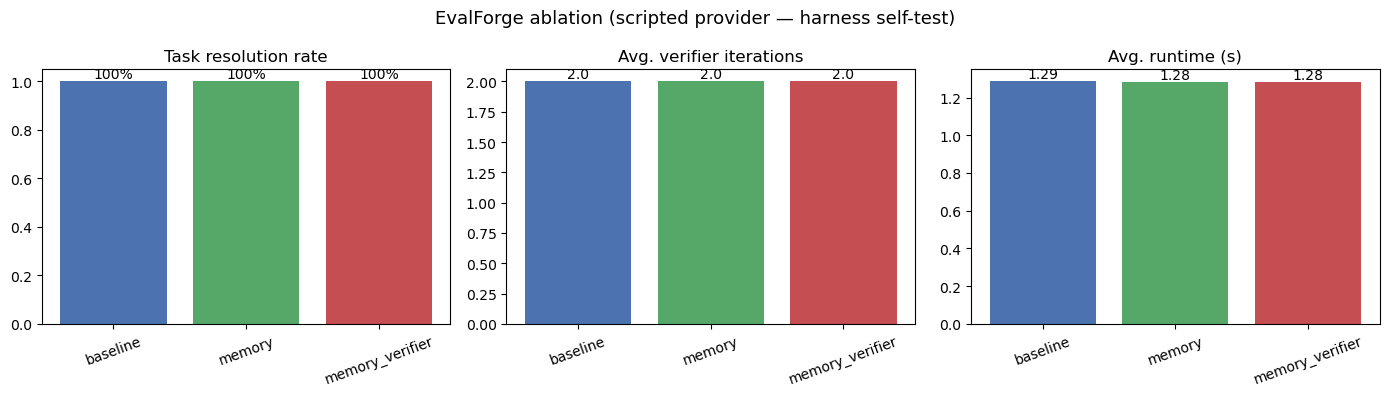

In [61]:
import matplotlib.pyplot as plt

m = metrics.reset_index()
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
palette = ["#4C72B0", "#55A868", "#C44E52"]
for ax, col, title, fmt in [
    (axes[0], "task_resolution_rate", "Task resolution rate", "{:.0%}"),
    (axes[1], "average_iterations",   "Avg. verifier iterations", "{:.1f}"),
    (axes[2], "average_runtime_seconds", "Avg. runtime (s)", "{:.2f}"),
]:
    bars = ax.bar(m["condition"], m[col], color=palette)
    ax.set_title(title); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
    if col == "task_resolution_rate":
        ax.set_ylim(0, 1.05)
    for b, v in zip(bars, m[col]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height(), fmt.format(v),
                ha="center", va="bottom", fontsize=10)
fig.suptitle("EvalForge ablation (scripted provider — harness self-test)", fontsize=13)
fig.tight_layout()
plt.show()

> **Reading the plots.** Every bar is identical and every resolution rate is
> 100%. That is the *expected and correct* result for a scripted provider: the
> replayed repairs are known‑good, so the three conditions cannot differ. What
> this demonstrates is that the **harness** is sound — containment holds, the
> submit/evaluator gates work, memory seeds and retrieves without leakage, and
> scoring is consistent. Differences between the bars only emerge when a *real
> model* drives the loop and sometimes fails, iterates, or benefits from a
> retrieved lesson.

## Demo 6 — memory provenance (auditability)

Every lesson carries where it came from: the originating task, the trace id, and the verifier evidence that justified it. Nothing is stored without proof.

In [64]:
prov = pd.DataFrame([{
    "id": r.memory_id, "from_task": r.task_id, "category": r.task_category,
    "outcome": r.outcome, "lesson": (r.lesson or "")[:70] + ("…" if len(r.lesson or "") > 70 else ""),
    "trace_id": r.trace_id,
} for r in MemoryStore(frozen).all()])
prov

,id,from_task,category,outcome,lesson,trace_id
0,1,numpy_broadcast_001,numpy_shape_broadcasting,resolved,"For NumPy feature normalization, align reducti...",numpy_broadcast_001-254bbaf10d
1,2,regression_rmse_002,regression_metrics,resolved,"For regression_metrics, diagnose rmse omits th...",regression_rmse_002-312e713e77
2,3,numerical_log_003,numerical_stability,resolved,"For numerical_stability, diagnose logarithms a...",numerical_log_003-665d369707
3,4,pandas_leakage_004,pandas_data_leakage,resolved,"For pandas_data_leakage, diagnose preprocessin...",pandas_leakage_004-ef826c1a16
4,5,pytorch_zero_grad_005,pytorch_training_loop,resolved,"For pytorch_training_loop, diagnose optimizer ...",pytorch_zero_grad_005-a6d708cd5d
5,6,device_batch_006,device_dtype_mismatch,resolved,"For device_dtype_mismatch, diagnose target ten...",device_batch_006-1cc1912ee1
6,7,seed_isolation_007,random_seed_handling,resolved,"For random_seed_handling, diagnose function mu...",seed_isolation_007-95ff60bf65
7,8,units_nanometer_008,scientific_unit_conversion,resolved,"For scientific_unit_conversion, diagnose si co...",units_nanometer_008-334f543ace


---
## Where the science actually happens: plugging in a real model

Everything you ran used `ScriptedProvider`. To turn this from a harness self‑test
into a real experiment, implement **one** method — `next_action` — backed by an
LLM, and change nothing else:

```python
class MyLLMProvider:
    def __init__(self, model): self.model = model
    exhausted = False
    def next_action(self, context: "AgentContext") -> "ProviderResponse":
        # 1. Render context.issue, context.repository_files, context.previous_results,
        #    context.latest_verification, and context.memory into a prompt.
        # 2. If context.require_structured_diagnosis is True, force the model to
        #    return a FailureDiagnosis before it may apply a patch.
        # 3. Parse the model's reply into an AgentDecision (tool / submit / abort).
        ...
```

Then swap `ScriptedProvider(...)` for `MyLLMProvider("your-model")` in Demo 4.
The containment, gating, memory, tracing, and scoring you already trust stay
exactly as they are — which is the whole point of separating the harness from the
policy.

**What each condition then isolates**

* `baseline` → `memory`: does carrying lessons across tasks help?
* `memory` → `memory_verifier`: does *forcing evidence‑linked* iteration (no
  editing until you've cited the failing output) help beyond just having memory?

**Honest limitations.** The bundled suite is small (8 + 20) and hand‑built; the
scripted runs measure the harness, not a model; and "resolved" is only as strong
as the hidden evaluator tests. Those are the right caveats to keep in mind — and
the right things to expand next.